# LitScope-Lite: Feature Engineering, Normalization and Scaling


## Objectives

1. Derive interpretable numerical features from the cleaned SciFact claims and scientific abstracts.
2. Compute sparse lexical similarity using the TF-IDF configuration of the existing retrieval implementation.
3. Inspect feature distributions, skewness, and correlations before transformation.
4. Compare logarithmic transformation, standardization, and min–max normalization.
5. Fit numerical scalers exclusively on training observations and apply them to development observations.
6. Export reproducible tabular feature datasets, fitted transformers, visualizations, and validation metadata.



## 1. Environment and input integrity

The notebook reads the four schema-preserving outputs of `01_data_cleaning.ipynb` from `data/processed/`. The location is resolved automatically from the working directory. Input file hashes are recorded before feature extraction and verified after exporting derived artifacts.

SciFact abstracts are represented as ordered sentence arrays. Their sentence indices and gold evidence annotations are not modified.

In [1]:
from pathlib import Path
from collections import Counter
import hashlib
import json
import re

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import MinMaxScaler, StandardScaler

sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 140)

REQUIRED_FILE = Path('data/processed/corpus_clean.jsonl')
PROJECT_ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents] if (p / REQUIRED_FILE).is_file()),
    None
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        'Cleaned SciFact data not found. Generate data/processed/*.jsonl '
        'using notebooks/01_data_cleaning.ipynb.'
    )
DATA_DIR = PROJECT_ROOT / 'data' / 'processed'
FIGURE_DIR = PROJECT_ROOT / 'images'
REPORT_DIR = PROJECT_ROOT / 'outputs' / 'preprocessing'
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

INPUT_FILES = {
    'corpus': DATA_DIR / 'corpus_clean.jsonl',
    **{split: DATA_DIR / f'claims_{split}_clean.jsonl'
       for split in ('train', 'dev', 'test')}
}

def checksum(path):
    digest = hashlib.sha256()
    with path.open('rb') as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()

def read_jsonl(path):
    with path.open('r', encoding='utf-8') as stream:
        return [json.loads(line) for line in stream if line.strip()]

before_hashes = {name: checksum(path) for name, path in INPUT_FILES.items()}
records = {name: read_jsonl(path) for name, path in INPUT_FILES.items()}
corpus = records['corpus']
claims = {split: records[split] for split in ('train', 'dev', 'test')}
corpus_by_id = {int(doc['doc_id']): doc for doc in corpus}
assert len(corpus_by_id) == len(corpus), 'Duplicate document ID detected.'
assert all(isinstance(doc['abstract'], list) for doc in corpus)
assert all('id' in item and 'claim' in item for split in claims for item in claims[split])

inventory = pd.DataFrame([
    {'File': INPUT_FILES[key].name, 'Records': len(records[key])}
    for key in ('corpus', 'train', 'dev', 'test')
])
display(inventory)
print('Total corpus sentences:', f"{sum(len(doc['abstract']) for doc in corpus):,}")

,File,Records
0,corpus_clean.jsonl,5183
1,claims_train_clean.jsonl,809
2,claims_dev_clean.jsonl,300
3,claims_test_clean.jsonl,300


Total corpus sentences: 45,952


## 2. Feature definitions and sampling frame

Two feature tables are generated:

- **Claim-level table:** One row for each claim in the `train`, `dev`, and `test` splits. All features are calculated from claim text alone.
- **Claim–document table:** One row per cited claim–document pair in the `train` and `dev` splits. The SciFact test split does not supply cited document IDs, so no test pairs are inferred.

Repeated IDs within an individual claim's `cited_doc_ids` are collapsed **only in the derived pair table** so that each claim–document pair appears once. The original cleaned JSONL remains unchanged.

The pair table includes only observed `cited_doc_ids`; it does not treat the entire cartesian product of claims and documents as labeled data. `gold_stance` is populated only when the corresponding cited document has a gold evidence annotation. Other pairs have `UNANNOTATED` status, **not** an inferred `NOT_ENOUGH_INFO` classification.

Predictor features do not use evidence-rationale indices, the gold stance, or annotation status. These fields are retained solely as dataset metadata.

| Feature | Definition |
|---|---|
| `claim_word_count`, `claim_char_count` | Length of the claim in words and characters |
| `claim_numeric_token_ratio` | Fraction of claim tokens containing a digit |
| `claim_unique_token_ratio` | Unique-to-total lexical token ratio |
| `title_word_count` | Length of the candidate document title |
| `abstract_word_count`, `abstract_sentence_count` | Length of the candidate abstract |
| `abstract_numeric_token_ratio` | Fraction of abstract tokens containing a digit |
| `claim_abstract_jaccard` | Set-based lexical Jaccard similarity with the candidate abstract |
| `claim_title_jaccard` | Set-based lexical Jaccard similarity with the candidate title |
| `tfidf_sparse_score` | Cosine similarity from the TF-IDF claim and document vectors |

Whitespace splitting is used for word counts; lexical overlap and numeric token ratios use the same Unicode-aware tokenizer. No manually assigned biomedical entities or unsupported target labels are introduced.

In [2]:
TOKEN_RE = re.compile(r"\b[\w]+(?:[-'][\w]+)*\b", flags=re.UNICODE)

def word_count(text):
    return len(str(text).split())

def tokens(text):
    return TOKEN_RE.findall(str(text).casefold())

def numeric_ratio(token_list):
    return (sum(any(char.isdigit() for char in token) for token in token_list)
            / len(token_list)) if token_list else 0.0

def unique_ratio(token_list):
    return len(set(token_list)) / len(token_list) if token_list else 0.0

def jaccard(token_a, token_b):
    a, b = set(token_a), set(token_b)
    return len(a & b) / len(a | b) if (a or b) else 0.0

claim_rows = []
claim_cache = {}
for split in ('train', 'dev', 'test'):
    for item in claims[split]:
        claim_id = int(item['id'])
        content = item['claim']
        lexical_tokens = tokens(content)
        claim_cache[(split, claim_id)] = lexical_tokens
        claim_rows.append({
            'split': split,
            'claim_id': claim_id,
            'claim_word_count': word_count(content),
            'claim_char_count': len(content),
            'claim_numeric_token_ratio': numeric_ratio(lexical_tokens),
            'claim_unique_token_ratio': unique_ratio(lexical_tokens),
        })

claim_features = pd.DataFrame(claim_rows)
assert len(claim_features) == 1409
assert not claim_features.duplicated(['split', 'claim_id']).any()

doc_features = {}
for doc_id, doc in corpus_by_id.items():
    abstract = ' '.join(doc['abstract'])
    title = doc['title']
    abstract_tokens = tokens(abstract)
    doc_features[doc_id] = {
        'title_word_count': word_count(title),
        'abstract_word_count': word_count(abstract),
        'abstract_sentence_count': len(doc['abstract']),
        'abstract_numeric_token_ratio': numeric_ratio(abstract_tokens),
        'abstract_tokens': abstract_tokens,
        'title_tokens': tokens(title),
        'document_full_text': f'{title}. {abstract}',
    }

claim_attributes = claim_features.set_index(['split', 'claim_id']).to_dict(orient='index')

rows = []
duplicate_citation_references = []
for split in ('train', 'dev'):
    for item in claims[split]:
        claim_id = int(item['id'])
        evidence = item.get('evidence', {})
        cited_doc_ids = [int(doc_id) for doc_id in item.get('cited_doc_ids', [])]
        if len(cited_doc_ids) != len(set(cited_doc_ids)):
            duplicate_citation_references.append({
                'split': split, 'claim_id': claim_id,
                'duplicate_count': len(cited_doc_ids) - len(set(cited_doc_ids))
            })
        cited_doc_ids = list(dict.fromkeys(cited_doc_ids))
        if not set(map(int, evidence)).issubset(set(cited_doc_ids)):
            raise ValueError(f'Evidence document absent from cited IDs for {split}:{claim_id}')

        claim_meta = claim_attributes[(split, claim_id)]
        claim_tokens = claim_cache[(split, claim_id)]
        for doc_id in cited_doc_ids:
            if doc_id not in doc_features:
                raise ValueError(f'Cited document missing from corpus: {doc_id}')
            doc_meta = doc_features[doc_id]
            evidence_sets = evidence.get(str(doc_id), evidence.get(doc_id, []))
            annotation_labels = {entry['label'] for entry in evidence_sets}
            if len(annotation_labels) > 1:
                raise ValueError(f'Conflicting evidence stances: {split}:{claim_id}:{doc_id}')
            if not annotation_labels.issubset({'SUPPORT', 'CONTRADICT'}):
                raise ValueError(f'Unexpected gold stance: {annotation_labels}')
            row = {
                'split': split,
                'claim_id': claim_id,
                'doc_id': doc_id,
                'annotation_status': 'ANNOTATED' if evidence_sets else 'UNANNOTATED',
                'gold_stance': next(iter(annotation_labels)) if annotation_labels else None,
                **claim_meta,
                **{key: doc_meta[key] for key in (
                    'title_word_count', 'abstract_word_count',
                    'abstract_sentence_count', 'abstract_numeric_token_ratio')},
                'claim_abstract_jaccard': jaccard(claim_tokens, doc_meta['abstract_tokens']),
                'claim_title_jaccard': jaccard(claim_tokens, doc_meta['title_tokens']),
            }
            rows.append(row)

pair_features = pd.DataFrame(rows)
assert not pair_features.duplicated(['split', 'claim_id', 'doc_id']).any()
assert set(pair_features['split']) == {'train', 'dev'}
assert pair_features.loc[pair_features['annotation_status'] == 'UNANNOTATED', 'gold_stance'].isna().all()
display(pair_features.groupby(['split', 'annotation_status']).size().rename('Pairs').reset_index())
print('Claim-level observations:', len(claim_features))
print('Claim–document observations:', len(pair_features))
print('Repeated cited-document references (deduplicated in pair view):', duplicate_citation_references)

,split,annotation_status,Pairs
0,dev,ANNOTATED,209
1,dev,UNANNOTATED,130
2,train,ANNOTATED,564
3,train,UNANNOTATED,355


Claim-level observations: 1409
Claim–document observations: 1258
Repeated cited-document references (deduplicated in pair view): [{'split': 'dev', 'claim_id': 1245, 'duplicate_count': 1}]


## 3. TF-IDF lexical similarity feature

A TF-IDF representation is fitted to the **fixed, unlabeled SciFact corpus**. This mirrors the existing lexical retrieval configuration: unigram and bigram features, English stop-word filtering, maximum document frequency of 0.85, and sublinear term frequency. Each cited claim is compared with its associated corpus document.

This operation creates an unsupervised lexical similarity feature; it does not use stance labels or fit a predictive model. The separate numerical scalers in Section 5 are fitted on training pairs only. Dense MiniLM scores are intentionally excluded here because the uploaded dataset does not contain aligned claim and document embeddings; no substitute scores are fabricated.

In [3]:
corpus_doc_ids = [int(doc['doc_id']) for doc in corpus]
doc_row_by_id = {doc_id: index for index, doc_id in enumerate(corpus_doc_ids)}
corpus_texts = [doc_features[doc_id]['document_full_text'] for doc_id in corpus_doc_ids]

vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    stop_words='english',
    max_df=0.85,
    sublinear_tf=True,
)
document_matrix = vectorizer.fit_transform(corpus_texts)
claim_text_lookup = {
    (split, int(item['id'])): item['claim']
    for split, entries in claims.items() for item in entries
}
query_texts = [claim_text_lookup[(row.split, int(row.claim_id))]
               for row in pair_features.itertuples(index=False)]
query_matrix = vectorizer.transform(query_texts)
selected_doc_rows = [doc_row_by_id[int(doc_id)] for doc_id in pair_features['doc_id']]
selected_docs_matrix = document_matrix[selected_doc_rows]
pair_features['tfidf_sparse_score'] = np.asarray(
    query_matrix.multiply(selected_docs_matrix).sum(axis=1)
).ravel()

assert pair_features['tfidf_sparse_score'].between(-1e-12, 1 + 1e-12).all()
assert np.isfinite(pair_features['tfidf_sparse_score']).all()

FEATURE_COLUMNS = [
    'claim_word_count', 'claim_char_count',
    'claim_numeric_token_ratio', 'claim_unique_token_ratio',
    'title_word_count', 'abstract_word_count',
    'abstract_sentence_count', 'abstract_numeric_token_ratio',
    'claim_abstract_jaccard', 'claim_title_jaccard',
    'tfidf_sparse_score',
]
COUNT_COLUMNS = [
    'claim_word_count', 'claim_char_count',
    'title_word_count', 'abstract_word_count',
    'abstract_sentence_count',
]
RATIO_COLUMNS = [name for name in FEATURE_COLUMNS if name not in COUNT_COLUMNS]
assert pair_features[FEATURE_COLUMNS].notna().all().all()
assert np.isfinite(pair_features[FEATURE_COLUMNS].to_numpy(dtype=float)).all()
assert all((pair_features[column] >= 0).all() for column in FEATURE_COLUMNS)
assert all(pair_features[column].le(1 + 1e-10).all() for column in RATIO_COLUMNS)

display(pair_features[FEATURE_COLUMNS].describe().T.round(3))

,count,mean,std,min,25%,50%,75%,max
claim_word_count,1258.0,12.411,4.814,3.000,9.000,12.000,15.000,39.000
claim_char_count,1258.0,89.525,33.634,26.000,66.000,82.000,109.000,249.000
claim_numeric_token_ratio,1258.0,0.052,0.079,0.000,0.000,0.000,0.091,0.500
claim_unique_token_ratio,1258.0,0.968,0.058,0.571,0.941,1.000,1.000,1.000
title_word_count,1258.0,13.312,4.548,1.000,10.000,13.000,16.000,38.000
abstract_word_count,1258.0,219.092,107.915,55.000,149.000,175.000,267.000,1065.000
abstract_sentence_count,1258.0,9.167,4.185,3.000,6.000,8.000,11.000,42.000
abstract_numeric_token_ratio,1258.0,0.070,0.062,0.000,0.020,0.056,0.103,0.315
claim_abstract_jaccard,1258.0,0.054,0.031,0.000,0.033,0.049,0.068,0.215
claim_title_jaccard,1258.0,0.124,0.102,0.000,0.053,0.106,0.167,0.667


## 4. Distribution diagnostics

Count features are naturally nonnegative and may be right-skewed. A logarithmic transformation (`log1p`) compresses large counts while retaining zero-valued observations. Ratio and similarity features remain on their original scales before numerical scaling.

Skewness is reported for the training split because the training observations determine all subsequent transformation parameters. Outlying values are not silently deleted or winsorized.

,feature,train_skewness,train_min,train_median,train_max,abs_skewness
3,claim_unique_token_ratio,-1.970,0.654,1.000,1.000,1.970
2,claim_numeric_token_ratio,1.614,0.000,0.000,0.500,1.614
9,claim_title_jaccard,1.589,0.000,0.105,0.667,1.589
8,claim_abstract_jaccard,1.385,0.000,0.048,0.215,1.385
5,abstract_word_count,1.352,58.000,174.000,692.000,1.352
7,abstract_numeric_token_ratio,1.093,0.000,0.058,0.315,1.093
6,abstract_sentence_count,1.089,3.000,8.000,25.000,1.089
4,title_word_count,1.037,1.000,13.000,38.000,1.037
0,claim_word_count,0.803,3.000,12.000,39.000,0.803
1,claim_char_count,0.766,26.000,82.000,249.000,0.766


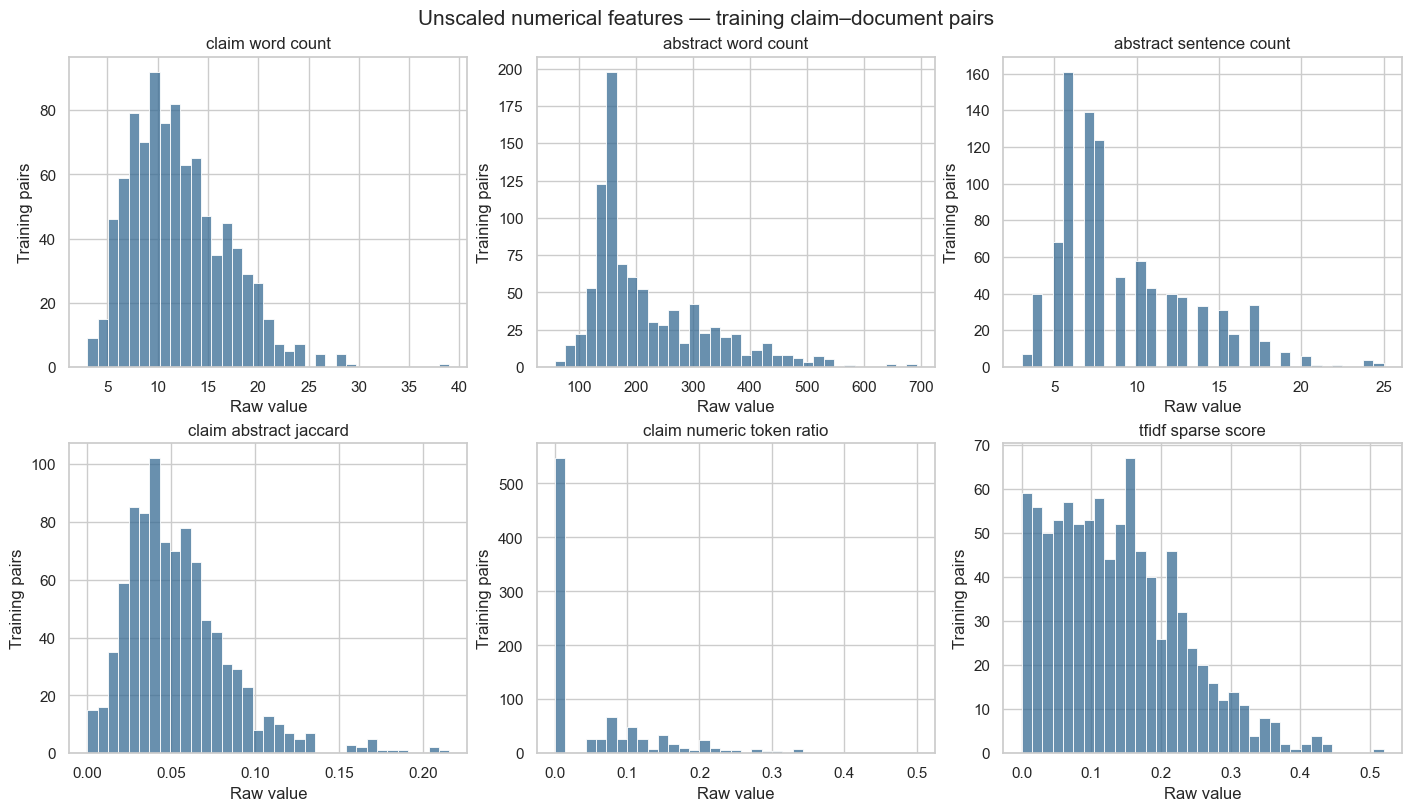

In [4]:
train_mask = pair_features['split'].eq('train')
dev_mask = pair_features['split'].eq('dev')
train_raw = pair_features.loc[train_mask, FEATURE_COLUMNS].copy()
dev_raw = pair_features.loc[dev_mask, FEATURE_COLUMNS].copy()

skewness_table = pd.DataFrame({
    'feature': FEATURE_COLUMNS,
    'train_skewness': [train_raw[name].skew() for name in FEATURE_COLUMNS],
    'train_min': [train_raw[name].min() for name in FEATURE_COLUMNS],
    'train_median': [train_raw[name].median() for name in FEATURE_COLUMNS],
    'train_max': [train_raw[name].max() for name in FEATURE_COLUMNS],
})
skewness_table['abs_skewness'] = skewness_table['train_skewness'].abs()
skewness_table.sort_values('abs_skewness', ascending=False, inplace=True)
display(skewness_table.round(3))
skewness_table.to_csv(REPORT_DIR / '03_training_feature_skewness.csv', index=False)

fig, axes = plt.subplots(2, 3, figsize=(14, 8), constrained_layout=True)
selected_features = [
    'claim_word_count', 'abstract_word_count', 'abstract_sentence_count',
    'claim_abstract_jaccard', 'claim_numeric_token_ratio', 'tfidf_sparse_score',
]
for ax, feature in zip(axes.flat, selected_features):
    sns.histplot(train_raw[feature], bins=35, color='#376b93', ax=ax)
    ax.set_title(feature.replace('_', ' '))
    ax.set_ylabel('Training pairs')
    ax.set_xlabel('Raw value')
fig.suptitle('Unscaled numerical features — training claim–document pairs', fontsize=15)
fig.savefig(FIGURE_DIR / '03_01_unscaled_feature_distributions.png', dpi=180, bbox_inches='tight')
plt.show()

### 4.1 Logarithmic transformation of count features

The `log1p(x)` operation is applied to count features only. The original feature values remain available in the exported raw table for interpretation and quality checks.

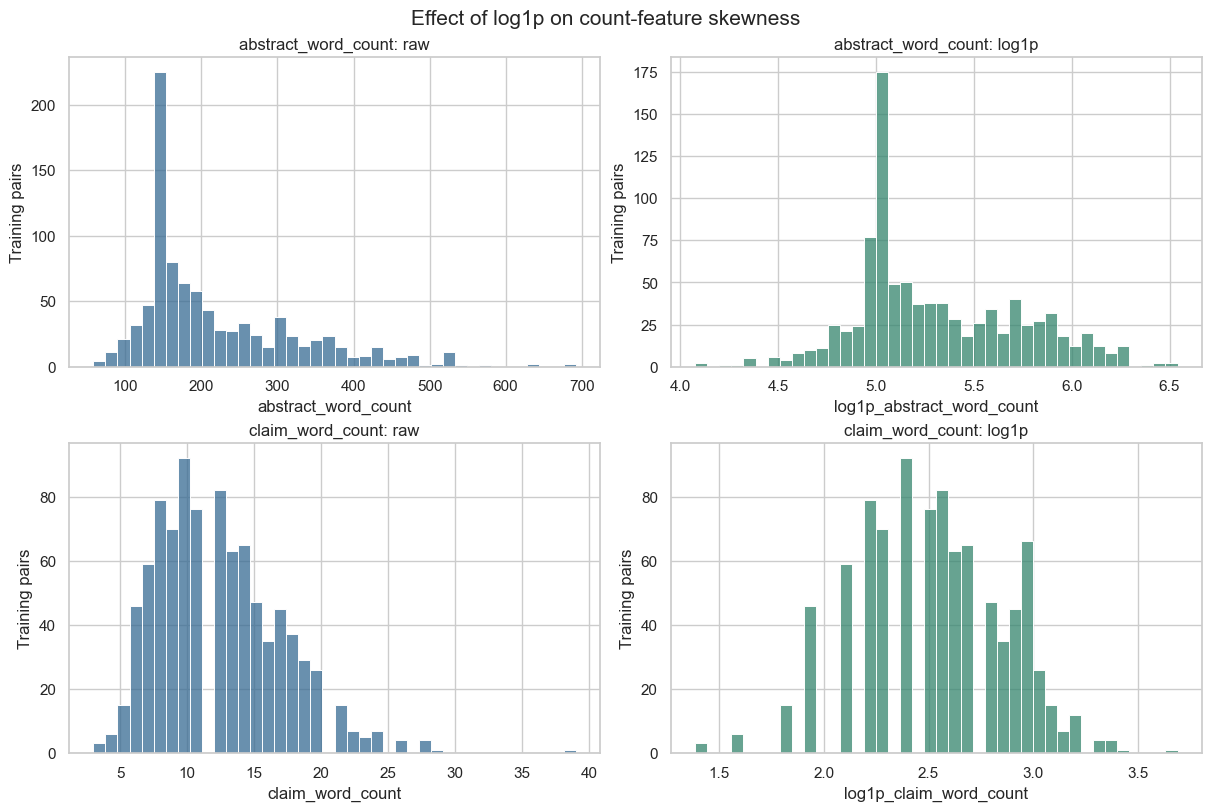

,feature,raw_skewness,log1p_skewness
0,claim_word_count,0.803,-0.153
1,claim_char_count,0.766,-0.124
2,title_word_count,1.037,-0.586
3,abstract_word_count,1.352,0.472
4,abstract_sentence_count,1.089,0.347


In [5]:
transformed = pair_features[FEATURE_COLUMNS].astype(float).copy()
for column in COUNT_COLUMNS:
    transformed[column] = np.log1p(transformed[column])
transformed.rename(columns={name: f'log1p_{name}' for name in COUNT_COLUMNS}, inplace=True)
TRANSFORMED_COLUMNS = transformed.columns.tolist()

fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
for i, field in enumerate(['abstract_word_count', 'claim_word_count']):
    sns.histplot(train_raw[field], bins=40, ax=axes[i, 0], color='#376b93')
    axes[i, 0].set_title(f'{field}: raw')
    axes[i, 0].set_ylabel('Training pairs')
    sns.histplot(transformed.loc[train_mask, f'log1p_{field}'], bins=40,
                 ax=axes[i, 1], color='#34856d')
    axes[i, 1].set_title(f'{field}: log1p')
    axes[i, 1].set_ylabel('Training pairs')
fig.suptitle('Effect of log1p on count-feature skewness', fontsize=15)
fig.savefig(FIGURE_DIR / '03_02_count_log_transformation.png', dpi=180, bbox_inches='tight')
plt.show()

skewness_comparison = pd.DataFrame({
    'feature': COUNT_COLUMNS,
    'raw_skewness': [train_raw[name].skew() for name in COUNT_COLUMNS],
    'log1p_skewness': [transformed.loc[train_mask, f'log1p_{name}'].skew()
                       for name in COUNT_COLUMNS],
})
display(skewness_comparison.round(3))

## 5. Train-only scaler fitting

`StandardScaler` centers each transformed numeric feature at the training mean and scales by the training standard deviation. `MinMaxScaler` maps the training range to [0, 1]. Both transformers are fitted **only on training claim–document pairs**. The development split is transformed using those fitted parameters, without refitting.

A development feature can legitimately fall outside the training range and therefore outside [0, 1] after min–max scaling. Clipping is deliberately avoided to preserve the observed distribution shift. No fitted transformations are inferred from the unannotated SciFact test claims.

These dataset-level transformers are distinct from the per-query min–max score normalization already used in the application's hybrid retrieval module.

In [6]:
train_X = transformed.loc[train_mask, TRANSFORMED_COLUMNS]
dev_X = transformed.loc[dev_mask, TRANSFORMED_COLUMNS]

standard_scaler = StandardScaler()
minmax_scaler = MinMaxScaler()
standard_scaler.fit(train_X)
minmax_scaler.fit(train_X)

standard_matrix = np.empty((len(pair_features), len(TRANSFORMED_COLUMNS)), dtype=float)
minmax_matrix = np.empty_like(standard_matrix)
standard_matrix[train_mask.to_numpy()] = standard_scaler.transform(train_X)
standard_matrix[dev_mask.to_numpy()] = standard_scaler.transform(dev_X)
minmax_matrix[train_mask.to_numpy()] = minmax_scaler.transform(train_X)
minmax_matrix[dev_mask.to_numpy()] = minmax_scaler.transform(dev_X)

standard_columns = [f'std_{column}' for column in TRANSFORMED_COLUMNS]
minmax_columns = [f'minmax_{column}' for column in TRANSFORMED_COLUMNS]
standard_df = pd.DataFrame(standard_matrix, columns=standard_columns, index=pair_features.index)
minmax_df = pd.DataFrame(minmax_matrix, columns=minmax_columns, index=pair_features.index)

assert np.isfinite(standard_matrix).all() and np.isfinite(minmax_matrix).all()
assert np.allclose(standard_scaler.mean_, train_X.mean().to_numpy())
assert np.allclose(standard_matrix[train_mask.to_numpy()].mean(axis=0), 0, atol=1e-9)
assert np.all(minmax_matrix[train_mask.to_numpy()] >= -1e-10)
assert np.all(minmax_matrix[train_mask.to_numpy()] <= 1 + 1e-10)
assert all(len(x) == len(pair_features) for x in [standard_df, minmax_df])

scale_summary = pd.DataFrame({
    'feature': TRANSFORMED_COLUMNS,
    'training_mean': standard_scaler.mean_,
    'training_std': standard_scaler.scale_,
    'training_min': minmax_scaler.data_min_,
    'training_max': minmax_scaler.data_max_,
})
display(scale_summary.round(4))

,feature,training_mean,training_std,training_min,training_max
0,log1p_claim_word_count,2.5296,0.3510,1.3863,3.6889
1,log1p_claim_char_count,4.4344,0.3592,3.2958,5.5215
2,claim_numeric_token_ratio,0.0533,0.0791,0.0000,0.5000
3,claim_unique_token_ratio,0.9696,0.0548,0.6538,1.0000
4,log1p_title_word_count,2.6120,0.3284,0.6931,3.6636
5,log1p_abstract_word_count,5.3014,0.4226,4.0775,6.5410
6,log1p_abstract_sentence_count,2.2481,0.3709,1.3863,3.2581
7,abstract_numeric_token_ratio,0.0716,0.0621,0.0000,0.3147
8,claim_abstract_jaccard,0.0538,0.0309,0.0000,0.2154
9,claim_title_jaccard,0.1250,0.1029,0.0000,0.6667


## 6. Scaling comparison and feature relationships

Visualization is used to inspect the numerical consequences of each transformation rather than presume that one scaler improves classification. Linear scaling alters feature location and spread but does not remove skewness; `log1p` addresses the skew of nonnegative counts before scaling.

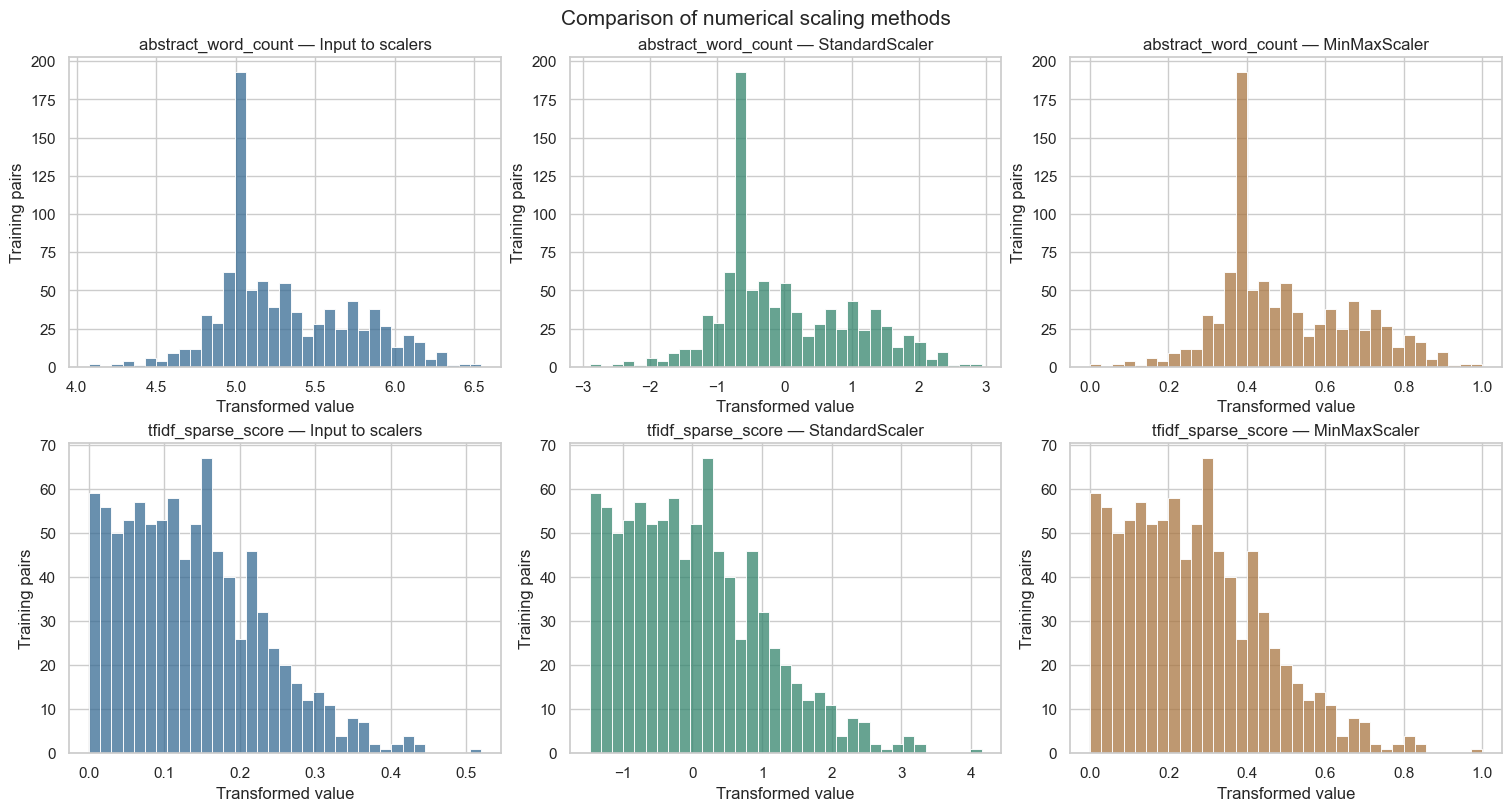

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8), constrained_layout=True)
comparison_features = ['abstract_word_count', 'tfidf_sparse_score']
for row, original in enumerate(comparison_features):
    model_col = f'log1p_{original}' if original in COUNT_COLUMNS else original
    series = [
        (transformed.loc[train_mask, model_col], 'Input to scalers', '#376b93'),
        (standard_df.loc[train_mask, f'std_{model_col}'], 'StandardScaler', '#34856d'),
        (minmax_df.loc[train_mask, f'minmax_{model_col}'], 'MinMaxScaler', '#a97642'),
    ]
    for col, (values, name, color) in enumerate(series):
        sns.histplot(values, bins=35, ax=axes[row, col], color=color)
        axes[row, col].set_title(f'{original} — {name}')
        axes[row, col].set_xlabel('Transformed value')
        axes[row, col].set_ylabel('Training pairs')
fig.suptitle('Comparison of numerical scaling methods', fontsize=15)
fig.savefig(FIGURE_DIR / '03_03_standard_vs_minmax.png', dpi=180, bbox_inches='tight')
plt.show()

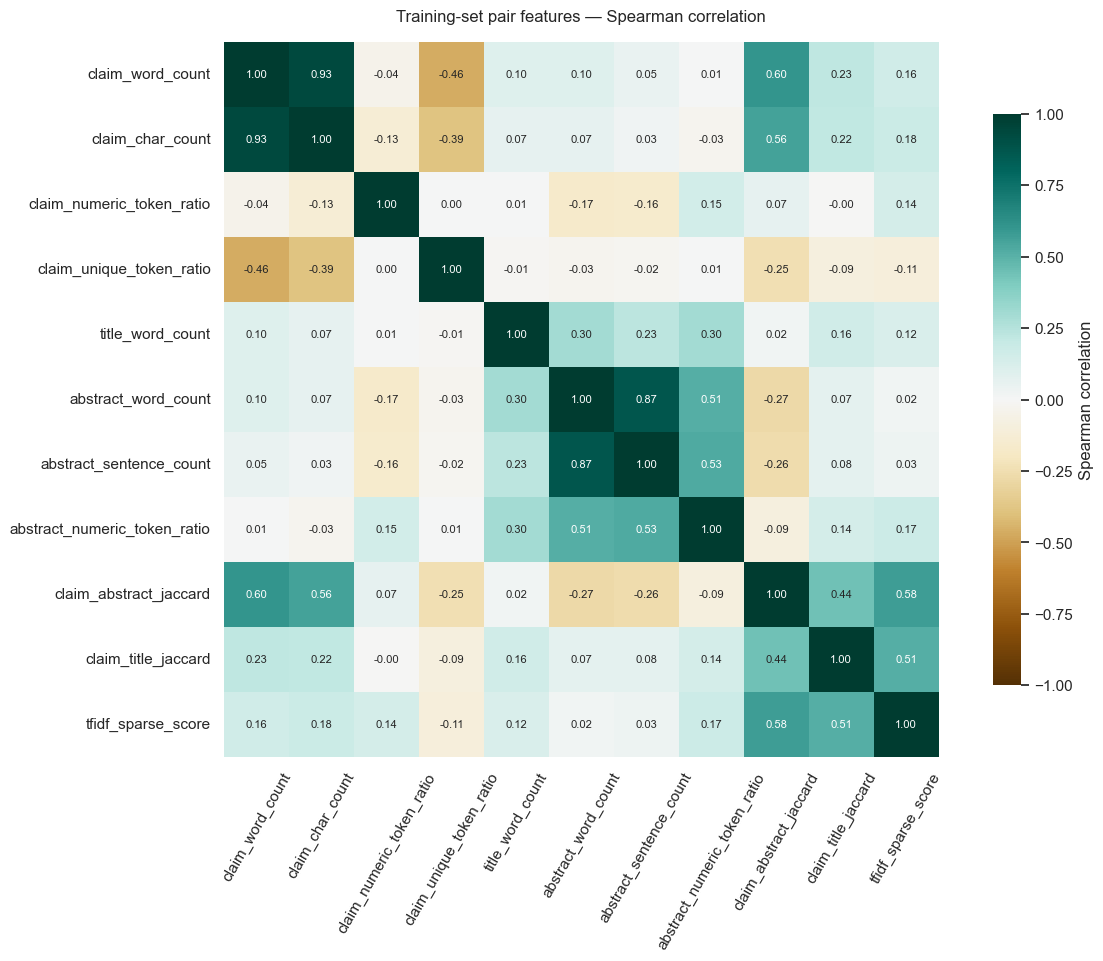

In [8]:
all_corr = train_raw[FEATURE_COLUMNS].corr(method='spearman')
fig, ax = plt.subplots(figsize=(11.5, 9.5), constrained_layout=True)
sns.heatmap(all_corr, annot=True, vmin=-1, vmax=1, cmap='BrBG', fmt='.2f',
            annot_kws={'size': 8}, square=True, ax=ax,
            cbar_kws={'shrink': 0.8, 'label': 'Spearman correlation'})
ax.set_title('Training-set pair features — Spearman correlation', pad=15)
ax.tick_params(axis='x', labelrotation=60)
ax.tick_params(axis='y', labelrotation=0)
fig.savefig(FIGURE_DIR / '03_04_feature_spearman_correlations.png', dpi=180, bbox_inches='tight')
plt.show()

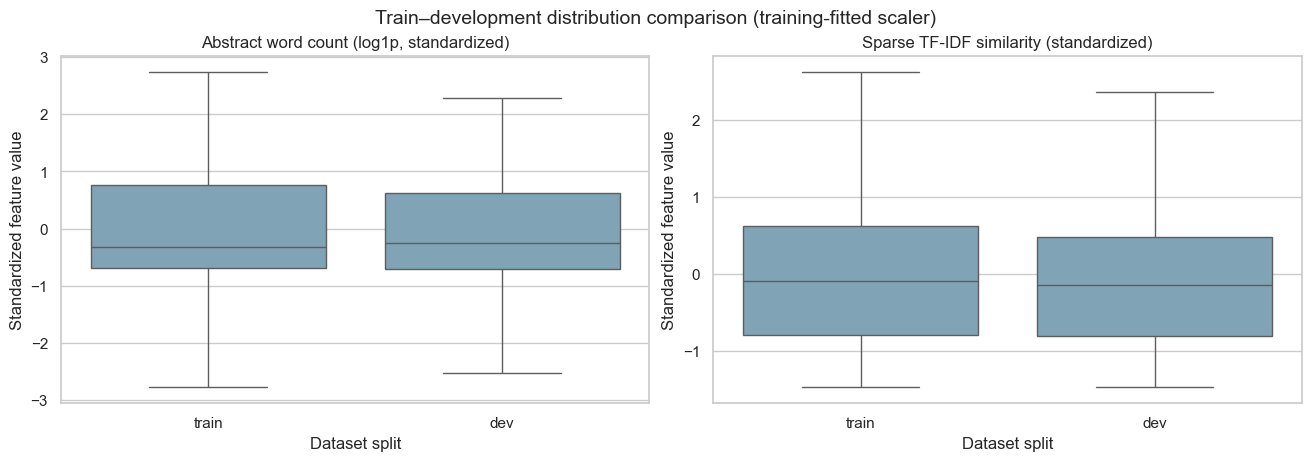

In [9]:
# Distribution comparison after fitting the scalers on the training split.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)
plot_frame = pd.DataFrame({
    'split': pair_features['split'],
    'standardized_abstract_length': standard_df['std_log1p_abstract_word_count'],
    'standardized_tfidf': standard_df['std_tfidf_sparse_score'],
})
for ax, field, title in zip(
    axes,
    ['standardized_abstract_length', 'standardized_tfidf'],
    ['Abstract word count (log1p, standardized)', 'Sparse TF-IDF similarity (standardized)']
):
    sns.boxplot(data=plot_frame, x='split', y=field, order=['train','dev'],
                color='#78a6bf', showfliers=False, ax=ax)
    ax.set_title(title)
    ax.set_ylabel('Standardized feature value')
    ax.set_xlabel('Dataset split')
fig.suptitle('Train–development distribution comparison (training-fitted scaler)', fontsize=14)
fig.savefig(FIGURE_DIR / '03_05_train_dev_feature_comparison.png', dpi=180, bbox_inches='tight')
plt.show()

## 7. Export of processed datasets and fitted transformers

The raw and processed pair tables retain `split`, `claim_id`, and `doc_id` for traceability. The gold annotation fields are kept as metadata and are **excluded from both fitted scalers**. Both standardized and min–max feature representations are exported to allow explicit downstream selection.

The original cleaned JSONL files remain unchanged. Stored scaler objects and metadata make transformations reproducible without recalculating parameters on development observations.

In [10]:
raw_csv = DATA_DIR / 'scifact_features_raw.csv'
scaled_csv = DATA_DIR / 'scifact_features_scaled.csv'
claim_csv = DATA_DIR / 'scifact_claim_features.csv'
scaler_file = DATA_DIR / 'scifact_scalers.joblib'
metadata_file = DATA_DIR / 'scifact_feature_scaling_metadata.json'
summary_file = REPORT_DIR / '03_preprocessing_summary.json'

PAIR_ID_COLS = ['split', 'claim_id', 'doc_id', 'annotation_status', 'gold_stance']
raw_out = pair_features[PAIR_ID_COLS + FEATURE_COLUMNS].copy()
scaled_out = pd.concat([pair_features[PAIR_ID_COLS], standard_df, minmax_df], axis=1)

claim_features.to_csv(claim_csv, index=False)
raw_out.to_csv(raw_csv, index=False)
scaled_out.to_csv(scaled_csv, index=False)
joblib.dump({
    'standard_scaler': standard_scaler,
    'minmax_scaler': minmax_scaler,
    'source_feature_columns': FEATURE_COLUMNS,
    'count_feature_columns': COUNT_COLUMNS,
    'transformed_feature_columns': TRANSFORMED_COLUMNS,
}, scaler_file)

by_split = (
    pair_features.groupby('split')
    .agg(pairs=('doc_id', 'size'),
         distinct_claims=('claim_id', 'nunique'),
         median_tfidf_score=('tfidf_sparse_score', 'median'),
         mean_claim_length=('claim_word_count', 'mean'),
         mean_abstract_length=('abstract_word_count', 'mean'))
    .reset_index()
)
by_split.to_csv(REPORT_DIR / '03_pair_feature_summary_by_split.csv', index=False)

metadata = {
    'project': 'LitScope-Lite',
    'dataset': 'SciFact (schema-preserving cleaned JSONL)',
    'observation_unit': 'one cited claim-document pair',
    'input_files': {name: path.relative_to(PROJECT_ROOT).as_posix()
                    for name, path in INPUT_FILES.items()},
    'input_sha256': before_hashes,
    'claim_counts': {split: len(claims[split]) for split in ('train', 'dev', 'test')},
    'pair_counts': {split: int(pair_features['split'].eq(split).sum())
                    for split in ('train', 'dev')},
    'total_pair_rows': int(len(pair_features)),
    'raw_features': FEATURE_COLUMNS,
    'log1p_features': COUNT_COLUMNS,
    'scaler_input_columns': TRANSFORMED_COLUMNS,
    'scaler_fit_split': 'train',
    'scaler_transform_splits': ['train', 'dev'],
    'gold_stance_in_predictors': False,
    'unannotated_pairs_assumed_nei': False,
    'tfidf': {
        'document_index': 'full SciFact corpus, title plus abstract',
        'ngram_range': [1, 2],
        'stop_words': 'english',
        'max_df': 0.85,
        'sublinear_tf': True,
        'score_interpretation': 'TF-IDF cosine similarity, not a stance prediction',
    },
    'dense_cosine_score_included': False,
    'dense_note': 'No aligned claim embeddings were supplied; dense scores were not fabricated.',
    'repeated_cited_reference_rows': duplicate_citation_references,
    'test_pair_rows': 0,
    'test_note': 'SciFact test claims do not include cited_doc_ids.',
    'scaled_csv_columns': scaled_out.columns.tolist(),
    'figure_files': sorted(path.name for path in FIGURE_DIR.glob('03_*.png')),
}
metadata_file.write_text(json.dumps(metadata, indent=2, ensure_ascii=False) + '\n', encoding='utf-8')
summary = {
    'pair_counts': metadata['pair_counts'],
    'claim_counts': metadata['claim_counts'],
    'annotation_status_counts': {
        f'{split}:{status}': int(number)
        for (split, status), number in pair_features.groupby(['split','annotation_status']).size().items()
    },
    'feature_counts': {'raw': len(FEATURE_COLUMNS), 'scaled_per_method': len(TRANSFORMED_COLUMNS)},
    'training_tfidf_scores': {
        'median': float(train_raw['tfidf_sparse_score'].median()),
        'mean': float(train_raw['tfidf_sparse_score'].mean()),
    },
    'raw_vs_log_skewness': skewness_comparison.to_dict(orient='records'),
    'output_files': {
        'raw_pairs': raw_csv.relative_to(PROJECT_ROOT).as_posix(),
        'scaled_pairs': scaled_csv.relative_to(PROJECT_ROOT).as_posix(),
        'claim_features': claim_csv.relative_to(PROJECT_ROOT).as_posix(),
        'scalers': scaler_file.relative_to(PROJECT_ROOT).as_posix(),
        'metadata': metadata_file.relative_to(PROJECT_ROOT).as_posix(),
    },
}
summary_file.write_text(json.dumps(summary, indent=2, ensure_ascii=False) + '\n', encoding='utf-8')

print('Saved claim features:', claim_csv.relative_to(PROJECT_ROOT))
print('Saved raw cited-pair features:', raw_csv.relative_to(PROJECT_ROOT))
print('Saved scaled cited-pair features:', scaled_csv.relative_to(PROJECT_ROOT))
print('Saved fitted scalers:', scaler_file.relative_to(PROJECT_ROOT))
display(by_split.round(3))

Saved claim features: data\processed\scifact_claim_features.csv
Saved raw cited-pair features: data\processed\scifact_features_raw.csv
Saved scaled cited-pair features: data\processed\scifact_features_scaled.csv
Saved fitted scalers: data\processed\scifact_scalers.joblib


,split,pairs,distinct_claims,median_tfidf_score,mean_claim_length,mean_abstract_length
0,dev,339,300,0.122,12.631,217.965
1,train,919,809,0.127,12.330,219.508


## 8. Empirical findings and methodological limitations

The numerical statements in this section are computed from the actual SciFact files and training-fitted transformations.

In [11]:
train_tfidf = train_raw['tfidf_sparse_score']
count_skew = skewness_comparison.set_index('feature')
biggest_count = skewness_table.iloc[0]
train_std = standard_df.loc[train_mask, :]
dev_std = standard_df.loc[dev_mask, :]
within_range = np.all((minmax_matrix[dev_mask.to_numpy()] >= -1e-10) &
                      (minmax_matrix[dev_mask.to_numpy()] <= 1 + 1e-10), axis=1)

finding_lines = [
    f'**Sampling frame:** {len(pair_features):,} cited claim–document pairs '
    f'({int(train_mask.sum()):,} training; {int(dev_mask.sum()):,} development). '
    f'The test split contains {len(claims["test"]):,} claims but no cited-document field.',
    f'**Feature availability:** {len(FEATURE_COLUMNS)} text-derived or lexical features were '
    f'computed without gold evidence labels. Training TF-IDF scores have median '
    f'{train_tfidf.median():.3f} (range {train_tfidf.min():.3f}–{train_tfidf.max():.3f}).',
    f'**Length transformation:** Abstract word-count skewness changed from '
    f'{count_skew.loc["abstract_word_count","raw_skewness"]:.2f} to '
    f'{count_skew.loc["abstract_word_count","log1p_skewness"]:.2f} after log1p. '
    f'Large counts were compressed without removing observations.',
    f'**Scaler diagnostics:** Training-set standardized features have mean approximately zero. '
    f'{int(within_range.sum()):,}/{len(within_range):,} development pairs have every '
    f'min–max feature within the corresponding training interval.',
    '**Interpretation:** Feature correlations are descriptive associations, not evidence of '
    'causal relationships or improved verification accuracy. Sparse TF-IDF scores describe '
    'lexical similarity but do not determine entailment or contradiction.',
    '**Limitations:** Cited pairs are a biased subset of possible claim–document pairs. '
    'Unannotated pairs have no asserted stance class. No dense MiniLM scores, synthetic '
    'NEI labels, or test-set pair features are introduced.',
]
display(Markdown('\n\n'.join(f'- {line}' for line in finding_lines)))

- **Sampling frame:** 1,258 cited claim–document pairs (919 training; 339 development). The test split contains 300 claims but no cited-document field.

- **Feature availability:** 11 text-derived or lexical features were computed without gold evidence labels. Training TF-IDF scores have median 0.127 (range 0.000–0.520).

- **Length transformation:** Abstract word-count skewness changed from 1.35 to 0.47 after log1p. Large counts were compressed without removing observations.

- **Scaler diagnostics:** Training-set standardized features have mean approximately zero. 333/339 development pairs have every min–max feature within the corresponding training interval.

- **Interpretation:** Feature correlations are descriptive associations, not evidence of causal relationships or improved verification accuracy. Sparse TF-IDF scores describe lexical similarity but do not determine entailment or contradiction.

- **Limitations:** Cited pairs are a biased subset of possible claim–document pairs. Unannotated pairs have no asserted stance class. No dense MiniLM scores, synthetic NEI labels, or test-set pair features are introduced.

## 9. Reproducibility and data-integrity checks

These assertions verify that numeric transformations can be reproduced with saved scalers, that the development split did not influence fit parameters, and that all four cleaned JSONL source files are unmodified.

In [12]:
assert all(checksum(path) == before_hashes[name] for name, path in INPUT_FILES.items())
print('PASS 1/6 — Cleaned SciFact input files were not modified.')

assert len(claim_features) == sum(len(items) for items in claims.values())
assert len(raw_out) == len(scaled_out) == len(pair_features)
assert not scaled_out.duplicated(['split', 'claim_id', 'doc_id']).any()
print('PASS 2/6 — Claim and claim–document counts and identifiers are preserved.')

saved_transforms = joblib.load(scaler_file)
assert saved_transforms['transformed_feature_columns'] == TRANSFORMED_COLUMNS
assert np.allclose(saved_transforms['standard_scaler'].transform(train_X),
                   standard_df.loc[train_mask, standard_columns].to_numpy())
assert np.allclose(saved_transforms['minmax_scaler'].transform(dev_X),
                   minmax_df.loc[dev_mask, minmax_columns].to_numpy())
print('PASS 3/6 — Saved scalers reproduce training and development outputs.')

assert np.allclose(saved_transforms['standard_scaler'].mean_, train_X.mean().to_numpy())
assert not any(column in TRANSFORMED_COLUMNS for column in ['gold_stance', 'annotation_status'])
print('PASS 4/6 — Scaling parameters are training-only; target metadata is excluded.')

reloaded_raw = pd.read_csv(raw_csv)
reloaded_scaled = pd.read_csv(scaled_csv)
assert len(reloaded_raw) == len(reloaded_scaled) == len(pair_features)
assert np.isfinite(reloaded_scaled[standard_columns + minmax_columns].to_numpy()).all()
assert reloaded_scaled.loc[reloaded_scaled['annotation_status'].eq('UNANNOTATED'), 'gold_stance'].isna().all()
print('PASS 5/6 — All exported CSV files load; scaled values are finite and unlabeled pairs remain unlabeled.')

figures = sorted(FIGURE_DIR.glob('03_*.png'))
assert len(figures) >= 5 and all(path.stat().st_size > 5000 for path in figures)
assert metadata_file.is_file() and summary_file.is_file()
print(f'PASS 6/6 — {len(figures)} figures, metadata, and preprocessing summaries were exported.')

PASS 1/6 — Cleaned SciFact input files were not modified.
PASS 2/6 — Claim and claim–document counts and identifiers are preserved.
PASS 3/6 — Saved scalers reproduce training and development outputs.
PASS 4/6 — Scaling parameters are training-only; target metadata is excluded.
PASS 5/6 — All exported CSV files load; scaled values are finite and unlabeled pairs remain unlabeled.
PASS 6/6 — 5 figures, metadata, and preprocessing summaries were exported.
